# 온라인 쇼핑 구매 여부 예측 — PyTorch 분류 미니프로젝트

**모듈 1 · Day 2 · 8교시 / 학생용 TODO Notebook**

- **데이터:** `../data/online_shoppers_intention.csv` (`Revenue`: 구매 1 / 미구매 0)
- **개발:** pandas·scikit-learn(전처리·기준 모델·평가), PyTorch(MLP 구현·학습)
- **학습 흐름:** 클래스 불균형 → 기준 모델 → MLP-A/B → 임계값 분석 → 최종 모델
- **문서:** `02_classification_data_analysis.md`, `02_classification_model_analysis.md`, 통합 `adr.md`(③·④)

각 교시의 TODO를 작성한 후 순서대로 실행합니다. 자세한 설명은 과제 안내 교안을 확인하세요. **⑧교시는 공통 코드 실행·문서·제출 시간**입니다.

PyTorch 미설치 시 저장소 최상위 폴더에서 `uv add torch`를 실행하고 Notebook의 `.venv` 커널을 재시작합니다.

---
## ① 데이터 탐색 및 클래스 분포 — CP-01

**목표:** 데이터 구조·품질과 구매·미구매 비율을 확인합니다.

### ①-1. 데이터 불러오기 — 공통 코드

In [1]:
# [공통] 패키지·난수·데이터 경로
import copy
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

pd.set_option("display.max_columns", 40)
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cpu")
if torch.get_num_threads() > 4:
    torch.set_num_threads(4)

DATA_PATH = Path("../data/online_shoppers_intention.csv")
if not DATA_PATH.is_file():
    raise FileNotFoundError("../data/online_shoppers_intention.csv 경로를 확인하세요.")

TARGET = "Revenue"
df = pd.read_csv(DATA_PATH)
print("데이터 크기:", df.shape)
print("PyTorch:", torch.__version__, "| 장치:", DEVICE)
df.head()

데이터 크기: (12330, 18)
PyTorch: 2.15.0+cpu | 장치: cpu


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [2]:
# TODO 1-1. 컬럼 자료형과 기초 통계량을 확인합니다.
# 힌트: dtypes, describe(include="all"), display()
print(df.dtypes)
display(df.describe(include="all"))

Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                          str
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                    str
Weekend                       bool
Revenue                       bool
dtype: object


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330,12330.000000,12330.000000,12330.000000,12330.000000,12330,12330,12330
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10,NaN,NaN,NaN,NaN,3,2,2
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,May,NaN,NaN,NaN,NaN,Returning_Visitor,False,False
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3364,NaN,NaN,NaN,NaN,10551,9462,10422
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,NaN,2.124006,2.357097,3.147364,4.069586,NaN,NaN,NaN
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,NaN,0.911325,1.717277,2.401591,4.025169,NaN,NaN,NaN
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,1.000000,1.000000,1.000000,1.000000,NaN,NaN,NaN
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,NaN,2.000000,2.000000,1.000000,2.000000,NaN,NaN,NaN
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,NaN,2.000000,2.000000,3.000000,2.000000,NaN,NaN,NaN
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,NaN,3.000000,2.000000,4.000000,4.000000,NaN,NaN,NaN


### ①-2. 데이터 품질·주요 특성 분포 — TODO

In [4]:
# TODO 1-2. 결측값 개수와 중복 행 개수를 출력합니다.
# 힌트: isna().sum(), duplicated().sum()
print("결측값 개수:")
print(df.isna().sum())
print("\n중복 행 개수:")
print(df.duplicated().sum())

결측값 개수:
Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

중복 행 개수:
125


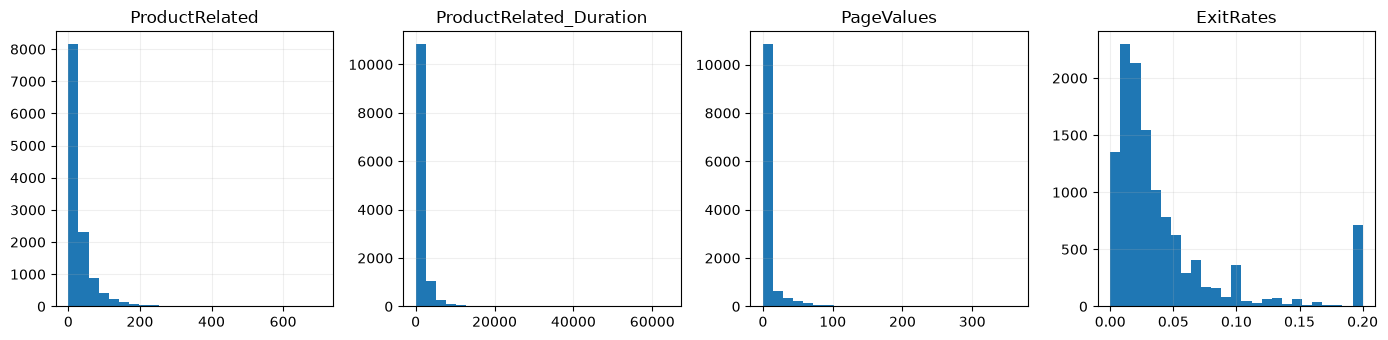

In [5]:
# [공통] 시각화할 특성과 그래프 틀
plot_cols = ["ProductRelated", "ProductRelated_Duration", "PageValues", "ExitRates"]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, col in zip(axes, plot_cols):
    # TODO 1-3. 각 특성의 히스토그램을 작성합니다.
    # 힌트: ax.hist(df[col], bins=25)
    ax.hist(df[col], bins=25)
    ax.set_title(col)
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### ①-3. 타깃 변환·클래스 분포 — TODO

In [6]:
# TODO 1-4. Revenue와 Weekend를 0/1 정수로 변환합니다.
# 힌트: astype(int)
df['Revenue'] = df['Revenue'].astype(int)
df['Weekend'] = df['Weekend'].astype(int)

In [7]:
# TODO 1-5. Revenue의 클래스별 건수와 비율을 계산합니다.
# 힌트: value_counts().sort_index(), value_counts(normalize=True)
class_counts = df['Revenue'].value_counts().sort_index()
class_rates = df['Revenue'].value_counts(normalize=True).sort_index()

# [공통] 결과표와 그래프 틀
class_summary = pd.DataFrame({
    "count": class_counts,
    "rate(%)": (class_rates * 100).round(2),
})
display(class_summary)

,count,rate(%)
Revenue,,
0,10422,84.53
1,1908,15.47


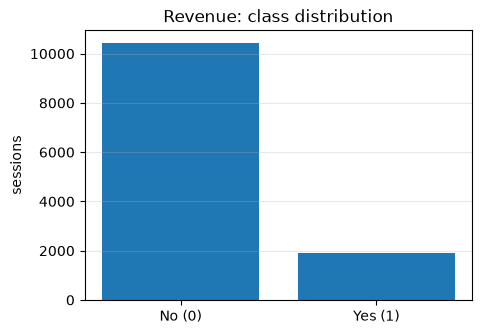

In [8]:
plt.figure(figsize=(5, 3.5))
# TODO 1-6. 구매·미구매 건수를 막대그래프로 시각화합니다.
# 힌트: plt.bar([...], class_counts.values)
plt.bar(['No (0)', 'Yes (1)'], class_counts.values)
plt.ylabel("sessions")
plt.title("Revenue: class distribution")
plt.grid(axis="y", alpha=0.3)
plt.show()

**[CP-01] 완료 기준:** 데이터 크기·결측값·중복 행과 구매 클래스 비율 및 분포 그래프를 확인합니다.

**기록:** `02_classification_data_analysis.md`

---
## ② 계층화 데이터 분할 및 특성 분석 — CP-02

**목표:** 구매 비율을 유지해 데이터를 분리하고 Train의 주요 특성을 비교합니다.

### ②-1. 입력·정답 구분과 계층화 분할 — TODO

In [9]:
from sklearn.model_selection import train_test_split

# TODO 2-1. Revenue를 제외한 입력 특성 FEATURES, X, y를 작성합니다.
FEATURES = df.columns.drop('Revenue')
X = df[FEATURES]
y = df['Revenue']

In [10]:
# TODO 2-2. stratify를 사용하여 Train 70%, Validation 15%, Test 15%로 나눕니다.
# 1) 전체 데이터의 15%를 Test로 분리
# 2) 나머지에서 0.15/0.85 비율을 Validation으로 분리
# random_state=SEED를 두 번 모두 지정합니다.
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.15, stratify=y, random_state=SEED)
X_train, X_valid, y_train, y_valid = train_test_split(X_dev, y_dev, test_size=0.15 / 0.85, stratify=y_dev, random_state=SEED)

# [공통] 분할 검증
for name, xx, yy in [
    ("Train", X_train, y_train),
    ("Validation", X_valid, y_valid),
    ("Test", X_test, y_test),
]:
    print(f"{name:<11} rows={len(xx):>5}  purchase_rate={yy.mean():.2%}")

assert len(X_train) + len(X_valid) + len(X_test) == len(df)
assert set(X_train.index).isdisjoint(X_valid.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_valid.index).isdisjoint(X_test.index)

Train       rows= 8630  purchase_rate=15.48%
Validation  rows= 1850  purchase_rate=15.46%
Test        rows= 1850  purchase_rate=15.46%


### ②-2. 방문자 유형별 구매율 — TODO

In [11]:
# [공통] Train 데이터만 활용한 특성 분석
train_view = X_train.copy()
train_view[TARGET] = y_train

# TODO 2-3. VisitorType별 세션 수(sessions)와 구매율(purchase_rate)을 계산합니다.
# 힌트: groupby(), agg(), sort_values()
visitor_rate = train_view.groupby("VisitorType").agg(sessions=("VisitorType", "count"), purchase_rate=(TARGET, "mean")).sort_values(by="sessions", ascending=False)
display(visitor_rate)

,sessions,purchase_rate
VisitorType,,
Returning_Visitor,7405,0.139500
New_Visitor,1162,0.252151
Other,63,0.158730


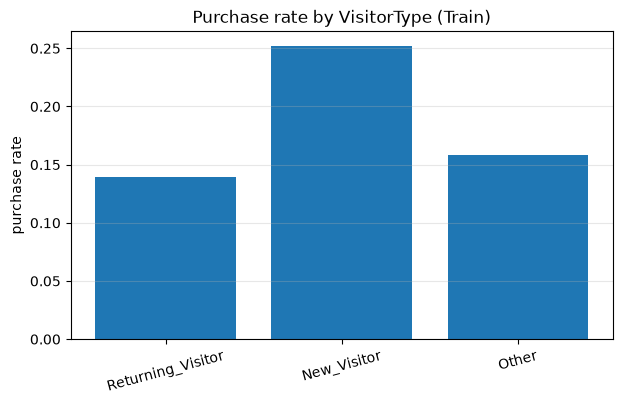

In [12]:
plt.figure(figsize=(7, 4))
# TODO 2-4. 방문자 유형별 구매율을 막대그래프로 나타냅니다.
# 힌트: plt.bar(visitor_rate.index.astype(str), visitor_rate["purchase_rate"])
plt.bar(visitor_rate.index.astype(str), visitor_rate["purchase_rate"])
plt.ylabel("purchase rate")
plt.title("Purchase rate by VisitorType (Train)")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.show()

### ②-3. 클래스별 행동 특성 중앙값 — TODO

In [13]:
# [공통] 구매·미구매 클래스별 비교 특성
compare_cols = ["ProductRelated", "ProductRelated_Duration", "PageValues", "ExitRates"]

# TODO 2-5. Revenue별 compare_cols 중앙값을 계산합니다.
# 힌트: groupby(TARGET)[compare_cols].median()
median_by_class = train_view.groupby(TARGET)[compare_cols].median()

# [공통] 결과 표시
median_by_class.index = ["미구매 (0)", "구매 (1)"]
display(median_by_class.round(3))

,ProductRelated,ProductRelated_Duration,PageValues,ExitRates
미구매 (0),16.0,517.580,0.000,0.029
구매 (1),29.0,1069.658,17.543,0.015


**[CP-02] 완료 기준:** Train·Validation·Test의 구매 비율과 Train 특성별 구매율·중앙값을 확인합니다.

---
## ③ 데이터 전처리 및 Tensor 준비 — CP-03

**목표:** 전처리 결과를 PyTorch가 학습할 수 있는 Tensor·DataLoader로 만듭니다.

### ③-1. 범주형·수치형·이진형 구분 — TODO

In [14]:
# TODO 3-1. FEATURES를 범주형·수치형·이진형으로 구분합니다.
# 범주형: Month, OperatingSystems, Browser, Region, TrafficType, VisitorType
# 수치형: 페이지 횟수·체류시간, BounceRates, ExitRates, PageValues, SpecialDay
# 이진형: Weekend
categorical_features = [
    "Month", "OperatingSystems", "Browser", "Region", "TrafficType", "VisitorType"
]

numeric_features = [
    "Administrative", "Administrative_Duration", 
    "Informational", "Informational_Duration", 
    "ProductRelated", "ProductRelated_Duration", 
    "BounceRates", "ExitRates", "PageValues", "SpecialDay"
]

binary_features = [
    "Weekend"
]

# [공통] 컬럼 목록 검사
assert set(categorical_features + numeric_features + binary_features) == set(FEATURES)
assert len(categorical_features + numeric_features + binary_features) == len(FEATURES)
print("특성 개수:", len(FEATURES))

특성 개수: 17


### ③-2. One-Hot 인코딩·표준화·ColumnTransformer — TODO

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def make_preprocessor():
    # TODO 3-2. 범주형 OneHotEncoder, 수치형 StandardScaler,
    # 이진형 passthrough를 ColumnTransformer로 결합합니다.
    # OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    return ColumnTransformer(
        transformers=[
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
            ("num", StandardScaler(), numeric_features),
            ("bin", "passthrough", binary_features)
        ]
    )


preprocessor = make_preprocessor()

In [16]:
# TODO 3-3. Train으로 전처리를 학습하고 Validation에 동일한 변환을 적용합니다.
# 힌트: fit_transform(), transform(), np.asarray(..., dtype=np.float32)
Xt_train = np.asarray(preprocessor.fit_transform(X_train), dtype=np.float32)
Xt_valid = np.asarray(preprocessor.transform(X_valid), dtype=np.float32)

# [공통] Shape와 유한값 검사
print("변환 전:", X_train.shape)
print("변환 후 Train:", Xt_train.shape, "/ Valid:", Xt_valid.shape)
assert Xt_train.shape[1] == Xt_valid.shape[1]
assert np.isfinite(Xt_train).all() and np.isfinite(Xt_valid).all()

변환 전: (8630, 17)
변환 후 Train: (8630, 73) / Valid: (1850, 73)


### ③-3. Tensor 변환·DataLoader — TODO

In [17]:
# TODO 3-4. 전처리된 입력과 타깃을 PyTorch float32 Tensor로 바꿉니다.
# 힌트: torch.from_numpy(), torch.tensor(..., dtype=torch.float32)
x_train_tensor = torch.tensor(Xt_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).unsqueeze(1)
x_valid_tensor = torch.tensor(Xt_valid, dtype=torch.float32)
y_valid_tensor = torch.tensor(y_valid.values, dtype=torch.float32).unsqueeze(1)

In [18]:
# TODO 3-5. 학습용 TensorDataset과 DataLoader를 만듭니다.
# batch_size=256, shuffle=True, generator=torch.Generator().manual_seed(SEED)
train_ds = TensorDataset(x_train_tensor, y_train_tensor)
train_loader = DataLoader(
    train_ds, 
    batch_size=256, 
    shuffle=True, 
    generator=torch.Generator().manual_seed(SEED)
)

# [공통] Tensor 형식과 배치 개수 확인
print("Tensor:", x_train_tensor.shape, y_train_tensor.shape)
print("dtype:", x_train_tensor.dtype, y_train_tensor.dtype)
print("Mini-batches:", len(train_loader))

Tensor: torch.Size([8630, 73]) torch.Size([8630, 1])
dtype: torch.float32 torch.float32
Mini-batches: 34


**[CP-03] 완료 기준:** Train 기반 전처리, `float32` Tensor 변환, 미니배치 생성과 입력 Shape를 확인합니다.

---
## ④ 기준 모델 및 Logistic Regression — CP-04

**목표:** 기준 모델을 학습하고 Accuracy·Precision·Recall·F1을 비교합니다.

### ④-1. Dummy·Logistic Regression 학습 — TODO

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression


# [공통] sklearn 모델 + 전처리 Pipeline

def make_sklearn_pipeline(estimator):
    return Pipeline([
        ("prep", make_preprocessor()),
        ("model", estimator),
    ])


# TODO 4-1. DummyClassifier(strategy="most_frequent")와
# LogisticRegression(max_iter=1500)을 Pipeline으로 구성합니다.
dummy_model = ...
logistic_model = ...

# [공통] 두 모델 학습
dummy_model.fit(X_train, y_train)
logistic_model.fit(X_train, y_train)

### ④-2. 분류 평가 함수·모델 비교 — TODO

In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
)


def classification_scores(y_true, y_pred):
    """구매 클래스(1) 기준 지표를 반환합니다."""
    # TODO 4-2. Accuracy·Precision·Recall·F1을 계산합니다.
    # Precision·Recall·F1은 zero_division=0으로 설정합니다.
    return {
        "Accuracy": ...,
        "Precision": ...,
        "Recall": ...,
        "F1": ...,
    }


# [공통] sklearn/MLP 모델 모두 사용할 결과 정리 함수
def summary_row(name, train_true, train_pred, valid_true, valid_pred):
    tr = classification_scores(train_true, train_pred)
    va = classification_scores(valid_true, valid_pred)
    return {
        "Model": name,
        **{f"Train {k}": v for k, v in tr.items()},
        **{f"Valid {k}": v for k, v in va.items()},
    }


# TODO 4-3. 두 기준 모델의 Train·Validation 예측값을 사용하여
# summary_row() 결과를 results 리스트에 저장합니다.
results = [
    # summary_row("DummyClassifier", ...),
    # summary_row("LogisticRegression", ...),
]
display(pd.DataFrame(results).round(3))

### ④-3. 혼동행렬 — TODO

In [ ]:
# TODO 4-4. LogisticRegression의 Validation 예측값을 생성합니다.
logistic_pred = ...

# TODO 4-5. confusion_matrix(..., labels=[0, 1])로 혼동행렬을 만듭니다.
logistic_cm = ...

# [공통] 결과 출력
logistic_cm = pd.DataFrame(
    logistic_cm,
    index=["Actual 0", "Actual 1"],
    columns=["Predicted 0", "Predicted 1"],
)
display(logistic_cm)
print(classification_report(y_valid, logistic_pred, zero_division=0))

**[CP-04] 완료 기준:** 두 모델의 성능표와 혼동행렬을 완성합니다.

**의사결정 ③:** 불균형 데이터에서 우선할 지표를 `adr.md`에 기록합니다.

---
## ⑤ PyTorch MLP-A 구현 및 학습 — CP-05

**목표:** 신경망 구조와 순전파·손실·역전파·가중치 갱신을 구현합니다.

### ⑤-1. MLP 구조·구매 확률 함수 — TODO

In [ ]:
# TODO 5-1. 입력 → 은닉층 64 → 은닉층 32 → 출력 1인 MLP를 구현합니다.
# 은닉층: Linear + ReLU, 첫 은닉층에는 Dropout(dropout) 적용
# 마지막 출력: Sigmoid 없이 logits(원시 점수) 반환
class PurchaseMLP(nn.Module):
    def __init__(self, input_dim, dropout=0.1):
        super().__init__()
        self.network = nn.Sequential(
            # nn.Linear(input_dim, 64), ...,
        )

    def forward(self, x):
        # TODO 5-2. 마지막 출력의 크기를 (batch,)로 맞춥니다.
        # 힌트: self.network(x).squeeze(1)
        return ...


# [공통] 모델의 logits를 구매 확률로 변환하는 함수 틀
def mlp_probabilities(model, X_scaled):
    model.eval()
    tensor = torch.from_numpy(np.asarray(X_scaled, dtype=np.float32))
    with torch.no_grad():
        # TODO 5-3. logits를 구하고 Sigmoid를 적용해 NumPy 배열로 반환합니다.
        # 힌트: torch.sigmoid(...).cpu().numpy()
        return ...


# [공통] 초기화·생성 코드
def make_mlp(input_dim):
    torch.manual_seed(SEED)
    return PurchaseMLP(input_dim=input_dim, dropout=0.1).to(DEVICE)


# [공통] 신경망 출력 형태 확인
probe = make_mlp(Xt_train.shape[1])
print(probe)
print("샘플 4건의 logits:", probe(x_train_tensor[:4]).detach().numpy())

### ⑤-2. 미니배치 학습·검증 함수 — TODO

In [ ]:
def train_one_epoch(model, loader, loss_fn, optimizer):
    """미니배치별 학습을 한 에포크 수행합니다."""
    model.train()
    losses = []
    for xb, yb in loader:
        # TODO 5-4. 기울기 초기화 → 순전파(logits) → 손실 계산 →
        # 역전파 → 가중치 갱신을 순서대로 구현합니다.
        # 힌트: zero_grad(), model(xb), loss_fn(), backward(), step()
        ...
        losses.append(float(loss.item()))
    return float(np.mean(losses))


def fit_mlp(Xtr, ytr, Xva, yva, *, positive_weight=None, epochs=25):
    """Validation F1 최고 에포크의 모델을 반환합니다."""
    # [공통] 모델·DataLoader·최고 검증 점수 기록 준비
    torch.manual_seed(SEED)
    model = make_mlp(Xtr.shape[1])
    loader = DataLoader(
        TensorDataset(
            torch.from_numpy(np.asarray(Xtr, dtype=np.float32)),
            torch.tensor(np.asarray(ytr), dtype=torch.float32),
        ),
        batch_size=256,
        shuffle=True,
        generator=torch.Generator().manual_seed(SEED),
    )

    # TODO 5-5. positive_weight가 None이면 일반 BCEWithLogitsLoss(),
    # 값이 있으면 pos_weight를 적용한 BCEWithLogitsLoss를 사용합니다.
    # 힌트: nn.BCEWithLogitsLoss(pos_weight=torch.tensor(float(positive_weight)))
    if positive_weight is None:
        loss_fn = ...
    else:
        loss_fn = ...

    # TODO 5-6. Adam 옵티마이저(lr=0.001)를 생성합니다.
    optimizer = ...

    # [공통] Validation F1이 가장 좋았던 에포크의 가중치 보관
    history = []
    best_f1 = -1.0
    best_epoch = 1
    best_state = None

    for epoch in range(1, epochs + 1):
        train_loss = train_one_epoch(model, loader, loss_fn, optimizer)
        train_prob = mlp_probabilities(model, Xtr)
        valid_prob = mlp_probabilities(model, Xva)

        # TODO 5-7. 확률 0.5 기준 예측 클래스를 만든 후
        # classification_scores()로 Train·Validation F1을 계산합니다.
        tr_f1 = ...
        va_f1 = ...

        # [공통] 학습 이력과 최고 검증 성능 기록
        history.append({
            "Epoch": epoch, "Train loss": train_loss,
            "Train F1": tr_f1, "Valid F1": va_f1,
        })
        if va_f1 > best_f1:
            best_f1 = va_f1
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    model.eval()
    return model, pd.DataFrame(history), best_epoch

### ⑤-3. MLP-A 학습·학습 곡선 — TODO

In [ ]:
# [공통] MLP-A: 클래스 가중치 없는 기본 BCE 학습
EPOCHS = 25
mlp_a, history_a, best_epoch_a = fit_mlp(
    Xt_train, y_train.to_numpy(), Xt_valid, y_valid.to_numpy(),
    positive_weight=None, epochs=EPOCHS,
)
print("MLP-A 최고 Validation F1 에포크:", best_epoch_a)
display(history_a.tail().round(3))

# TODO 5-8. Epoch별 Train loss, Train/Validation F1을 시각화합니다.
# 힌트: plt.subplots(1, 2, ...), ax.plot(history_a["Epoch"], ...)
...

**[CP-05] 완료 기준:** MLP-A의 logits·손실·학습 과정과 Train loss·F1 곡선을 확인합니다.

---
## ⑥ MLP-B 개선 및 모델 성능 비교 — CP-06

**목표:** 양성 클래스 가중 손실을 적용하고 MLP-A/B 성능을 비교합니다.

### ⑥-1. 클래스 가중 손실 적용 — TODO

In [ ]:
# TODO 6-1. Train에서 미구매·구매 건수를 구하고 pos_weight를 계산합니다.
# 힌트: pos_weight = 미구매 수 / 구매 수
n_negative = ...
n_positive = ...
pos_weight = ...
print("Train 불균형 비율(neg/pos):", round(pos_weight, 3))

# [공통] MLP-B: 가중 BCE 학습
mlp_b, history_b, best_epoch_b = fit_mlp(
    Xt_train, y_train.to_numpy(), Xt_valid, y_valid.to_numpy(),
    positive_weight=pos_weight, epochs=EPOCHS,
)
print("MLP-B 최고 Validation F1 에포크:", best_epoch_b)
display(history_b.tail().round(3))

### ⑥-2. 학습 곡선·전체 모델 비교 — TODO

In [ ]:
# TODO 6-2. MLP-A와 MLP-B의 Epoch별 Validation F1 곡선을 비교합니다.
# 힌트: history_a, history_b, plt.plot()
...

# [공통] 두 신경망 및 선택 에포크 보관
mlp_models = {
    "MLP-A (BCE)": mlp_a,
    "MLP-B (weighted BCE)": mlp_b,
}
mlp_best_epochs = {
    "MLP-A (BCE)": best_epoch_a,
    "MLP-B (weighted BCE)": best_epoch_b,
}

# TODO 6-3. 두 MLP의 Train·Validation 구매 확률을 계산하고
# 기본 임계값 0.5로 분류한 뒤, summary_row() 결과를 results에 추가합니다.
for name, model in mlp_models.items():
    tr_pred = ...
    va_pred = ...
    results.append(summary_row(name, y_train, tr_pred, y_valid, va_pred))

# TODO 6-4. 모델별 Valid F1 내림차순 정렬 및 Train-Valid F1 차이 계산
results_df = ...
results_df["Gap (Train-Valid F1)"] = ...
display(results_df.round(3))

**[CP-06] 완료 기준:** Dummy·Logistic Regression·MLP-A·MLP-B의 F1과 Precision·Recall을 비교합니다.

**선택 심화:** 가중 손실에 따른 FP·FN의 변화까지 분석합니다.

---
## ⑦ 분류 오류·임계값 분석 및 MLP 선택 — CP-07

**목표:** MLP-A/B의 FP·FN과 임계값별 성능을 비교해 최종 MLP를 선택합니다.

### ⑦-1. 두 MLP의 혼동행렬(임계값 0.5) — TODO

In [ ]:
# TODO 7-1. 각 MLP의 구매 확률을 0.5 기준으로 분류합니다.
# 그다음 혼동행렬에서 TN, FP, FN, TP를 계산합니다.
for name, model in mlp_models.items():
    p = ...
    pred = ...
    tn, fp, fn, tp = ...
    print(f"{name:<24} TN={tn:>5}  FP={fp:>4}  FN={fn:>4}  TP={tp:>4}")

### ⑦-2. 임계값 0.3·0.5·0.7 비교 — TODO

In [ ]:
# [공통] 분류 임계값과 결과 누적 구조
thresholds = [0.3, 0.5, 0.7]
threshold_records = []

for name, model in mlp_models.items():
    # TODO 7-2. 해당 모델의 Validation 구매 확률을 계산합니다.
    prob = ...
    for t in thresholds:
        # TODO 7-3. 확률을 t 기준으로 0/1 분류한 뒤 평가 지표와 혼동행렬을 계산합니다.
        pred = ...
        scores = ...
        tn, fp, fn, tp = ...
        # [공통] 모델별·임계값별 성능 기록
        threshold_records.append({
            "Model": name, "Threshold": t, **scores,
            "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
        })

threshold_df = pd.DataFrame(threshold_records)
display(threshold_df[[
    "Model", "Threshold", "Precision", "Recall", "F1", "FP", "FN"
]].round(3))

### ⑦-3. Precision·Recall·F1 시각화 — TODO

In [ ]:
# [공통] 성능 변화 그래프 기본 틀
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (name, part) in zip(axes, threshold_df.groupby("Model", sort=False)):
    for metric in ["Precision", "Recall", "F1"]:
        # TODO 7-4. threshold를 x축으로 지표의 변화를 표시합니다.
        # 힌트: ax.plot(part["Threshold"], part[metric], marker="o", label=metric)
        ...
    ax.set_title(name)
    ax.set_xticks(thresholds)
    ax.set_xlabel("decision threshold")
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_ylabel("purchase-class score")
plt.tight_layout()
plt.show()

### ⑦-4. 최종 MLP·임계값 선택 — TODO

In [ ]:
# TODO 7-5. Validation F1·Recall·Precision 내림차순으로 정렬합니다.
# 힌트: sort_values([...], ascending=False).reset_index(drop=True)
ranked = ...
display(ranked[[
    "Model", "Threshold", "F1", "Precision", "Recall", "FP", "FN"
]].round(3))

# TODO 7-6. 결과를 바탕으로 최종 MLP 이름과 분류 임계값을 직접 지정합니다.
# 모델명: "MLP-A (BCE)" 또는 "MLP-B (weighted BCE)"
# 임계값: 0.3, 0.5, 0.7 중 하나
# Test 결과를 확인하기 전에 결정합니다.
SELECTED_MODEL_NAME = ...
SELECTED_THRESHOLD = ...

# [공통] 선택 결과를 최종 재학습에 연결
assert SELECTED_MODEL_NAME in mlp_best_epochs
assert SELECTED_THRESHOLD in thresholds
SELECTED_EPOCHS = int(mlp_best_epochs[SELECTED_MODEL_NAME])
SELECTED_WEIGHTED = SELECTED_MODEL_NAME == "MLP-B (weighted BCE)"
print("최종 MLP:", SELECTED_MODEL_NAME)
print("최종 임계값:", SELECTED_THRESHOLD)
print("재학습 에포크:", SELECTED_EPOCHS)

**[CP-07] 완료 기준:** MLP별 FP·FN과 임계값별 성능을 비교하고 최종 모델·임계값을 지정합니다.

**의사결정 ④:** 선택 근거를 `adr.md`에 기록합니다. **선택 심화:** PR 곡선 분석.

---
## ⑧ 최종 실행 확인 및 프로젝트 제출 — CP-08

**목표:** 아래 공통 코드를 실행하고, 분석 문서·명세서·GitHub 제출을 완료합니다. **새로운 개발 TODO는 없습니다.**

### ⑧-1. 최종 재학습·Test 평가 — 공통 코드

In [ ]:
# [공통] 선택한 구조·손실·에포크 수를 고정하여 Train+Validation으로 재학습합니다.
X_trainval = pd.concat([X_train, X_valid])
y_trainval = pd.concat([y_train, y_valid])
final_preprocessor = make_preprocessor()
Xt_trainval = np.asarray(final_preprocessor.fit_transform(X_trainval), dtype=np.float32)
Xt_test = np.asarray(final_preprocessor.transform(X_test), dtype=np.float32)

final_model = make_mlp(Xt_trainval.shape[1])
final_ds = TensorDataset(
    torch.from_numpy(Xt_trainval),
    torch.tensor(y_trainval.to_numpy(), dtype=torch.float32),
)
final_loader = DataLoader(
    final_ds, batch_size=256, shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
)

if SELECTED_WEIGHTED:
    final_pos_weight = float((y_trainval == 0).sum() / (y_trainval == 1).sum())
    final_loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(final_pos_weight))
else:
    final_loss_fn = nn.BCEWithLogitsLoss()

final_optimizer = torch.optim.Adam(final_model.parameters(), lr=0.001)
for epoch in range(1, SELECTED_EPOCHS + 1):
    final_loss = train_one_epoch(final_model, final_loader, final_loss_fn, final_optimizer)
final_model.eval()

test_prob = mlp_probabilities(final_model, Xt_test)
test_pred = (test_prob >= SELECTED_THRESHOLD).astype(int)
test_scores = classification_scores(y_test, test_pred)
valid_row = threshold_df.loc[
    (threshold_df["Model"] == SELECTED_MODEL_NAME)
    & (threshold_df["Threshold"] == SELECTED_THRESHOLD)
].iloc[0]

print("최종 MLP:", SELECTED_MODEL_NAME, "/ threshold:", SELECTED_THRESHOLD)
print("Train+Validation:", len(X_trainval), "/ 최종 epoch:", SELECTED_EPOCHS)
print(f"{'Metric':<12}{'Test':>10}{'Valid(⑦)':>12}")
for metric in ["Accuracy", "Precision", "Recall", "F1"]:
    print(f"{metric:<12}{test_scores[metric]:>10.3f}{valid_row[metric]:>12.3f}")

cm_test = pd.DataFrame(
    confusion_matrix(y_test, test_pred, labels=[0, 1]),
    index=["Actual 0", "Actual 1"], columns=["Predicted 0", "Predicted 1"],
)
display(cm_test)

### ⑧-2. PyTorch 모델·전처리·설정 저장 — 공통 코드

In [ ]:
# [공통] 4개 산출물 규칙: joblib 번들 1개, JSON 1개, 비교표 CSV 2개
# joblib 번들 안에 PyTorch state_dict와 학습된 sklearn 전처리를 함께 보관합니다.
RESULTS_DIR = Path("../results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = RESULTS_DIR / "02_final_classifier.joblib"
CONFIG_PATH = RESULTS_DIR / "02_model_config.json"

model_bundle = {
    "preprocessor": final_preprocessor,
    "model_state_dict": {k: v.detach().cpu().clone() for k, v in final_model.state_dict().items()},
    "input_dim": int(Xt_trainval.shape[1]),
}
joblib.dump(model_bundle, MODEL_PATH, compress=3)

config = {
    "model_name": SELECTED_MODEL_NAME,
    "decision_threshold": SELECTED_THRESHOLD,
    "positive_class": 1,
    "features": FEATURES,
    "network": {"hidden_units": [64, 32], "dropout": 0.1},
    "training": {"epochs": SELECTED_EPOCHS, "weighted_loss": SELECTED_WEIGHTED, "seed": SEED},
}
CONFIG_PATH.write_text(json.dumps(config, indent=2, ensure_ascii=False), encoding="utf-8")

# 주의: joblib 파일은 본인이 생성했거나 신뢰하는 출처의 파일만 불러옵니다.
loaded_bundle = joblib.load(MODEL_PATH)
loaded_config = json.loads(CONFIG_PATH.read_text(encoding="utf-8"))
loaded_mlp = PurchaseMLP(
    input_dim=loaded_bundle["input_dim"],
    dropout=loaded_config["network"]["dropout"],
)
loaded_mlp.load_state_dict(loaded_bundle["model_state_dict"])
loaded_mlp.eval()

loaded_test_x = np.asarray(loaded_bundle["preprocessor"].transform(X_test), dtype=np.float32)
loaded_test_pred = (
    mlp_probabilities(loaded_mlp, loaded_test_x) >= loaded_config["decision_threshold"]
).astype(int)
print("저장 전후 예측 일치:", np.array_equal(test_pred, loaded_test_pred))

### ⑧-3. 구매 여부 예측 확인 — 공통 코드

In [ ]:
# [공통] 새 세션 1건의 원본 특성 → 저장된 전처리 → PyTorch 확률 → 임계값 판정

def predict_purchase(loaded_bundle, loaded_mlp, config, record):
    row = pd.DataFrame([record])[config["features"]]
    transformed = np.asarray(loaded_bundle["preprocessor"].transform(row), dtype=np.float32)
    probability = float(mlp_probabilities(loaded_mlp, transformed)[0])
    return {
        "purchase_probability": round(probability, 4),
        "prediction": int(probability >= config["decision_threshold"]),
        "threshold": float(config["decision_threshold"]),
    }

example = X_test.iloc[0].to_dict()
print("예측:", predict_purchase(loaded_bundle, loaded_mlp, loaded_config, example))
print("실제 Revenue:", int(y_test.iloc[0]))

### ⑧-4. 비교 CSV 2개 저장 — 공통 코드

In [ ]:
# [공통] 최종 Test 결과는 Notebook과 Analysis에만 기록합니다(별도 Test CSV 없음).
results_df.round(4).to_csv(RESULTS_DIR / "02_model_comparison.csv", index=False)
threshold_df.round(4).to_csv(RESULTS_DIR / "02_threshold_comparison.csv", index=False)
print("저장한 결과 파일:")
for p in sorted(RESULTS_DIR.glob("02_*")):
    print("-", p.name)

**[CP-08] 완료 기준:** Test 평가·모델 재로딩·예측·Analysis·ADR·명세서·GitHub 제출을 마무리합니다.

**결과 파일 4개:** `02_final_classifier.joblib`, `02_model_config.json`, `02_model_comparison.csv`, `02_threshold_comparison.csv`

**확인:** Test 결과를 본 뒤 모델·임계값을 다시 선택하지 않습니다.